# Optical Flow
## Sparse Optical Flow

As always start by importing the relevant packages.

In [11]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

Load the images `OF1.jpg` and `OF2.jpg` and change them to grayscale.

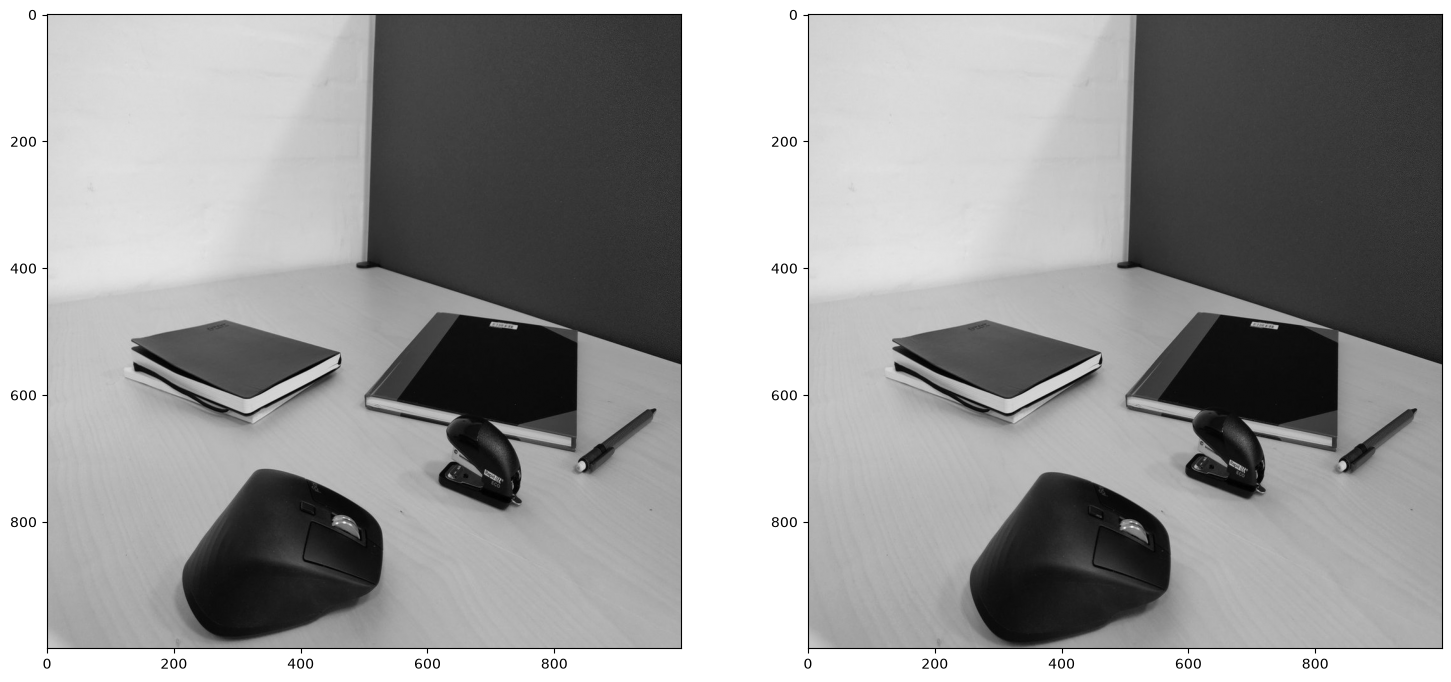

In [ ]:
img1 = cv2.imread('OF1.jpg')
img2 = cv2.imread('OF2.jpg')

b,g,r = cv2.split(img1) # Changing the order from bgr to rgb so that matplotlib can show it
img1 = cv2.merge([r,g,b])
b,g,r = cv2.split(img2) # Changing the order from bgr to rgb so that matplotlib can show it
img2 = cv2.merge([r,g,b])

gray1 = cv2.cvtColor(img1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_RGB2GRAY)

plt.figure(figsize = (18,18))
plt.subplot(1,2,1)
plt.imshow(gray1, cmap = 'gray')
plt.subplot(1,2,2)
plt.imshow(gray2, cmap = 'gray')

They look pretty much the same. We can now use optical flow to find out how the objects in the picutures have moved. We do this by first using [`cv2.goodFeaturesToTrack`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#ga1d6bb77486c8f92d79c8793ad995d541) to find features in the first image. You can play around with the parameters to see the difference.

In [13]:
feat1 = cv2.goodFeaturesToTrack(gray1, maxCorners=100, qualityLevel=0.3, minDistance=7)

Next we use the function [`cv2.calcOpticalFlowPyrLK`](https://docs.opencv.org/4.7.0/dc/d6b/group__video__track.html#ga473e4b886d0bcc6b65831eb88ed93323) to track the features in the next image.

In [14]:
feat2, status, error = cv2.calcOpticalFlowPyrLK(gray1, gray2, feat1, None)

We now have the location of the features from the first image in the second image. To find the movement, we can draw a line between the keypoints.

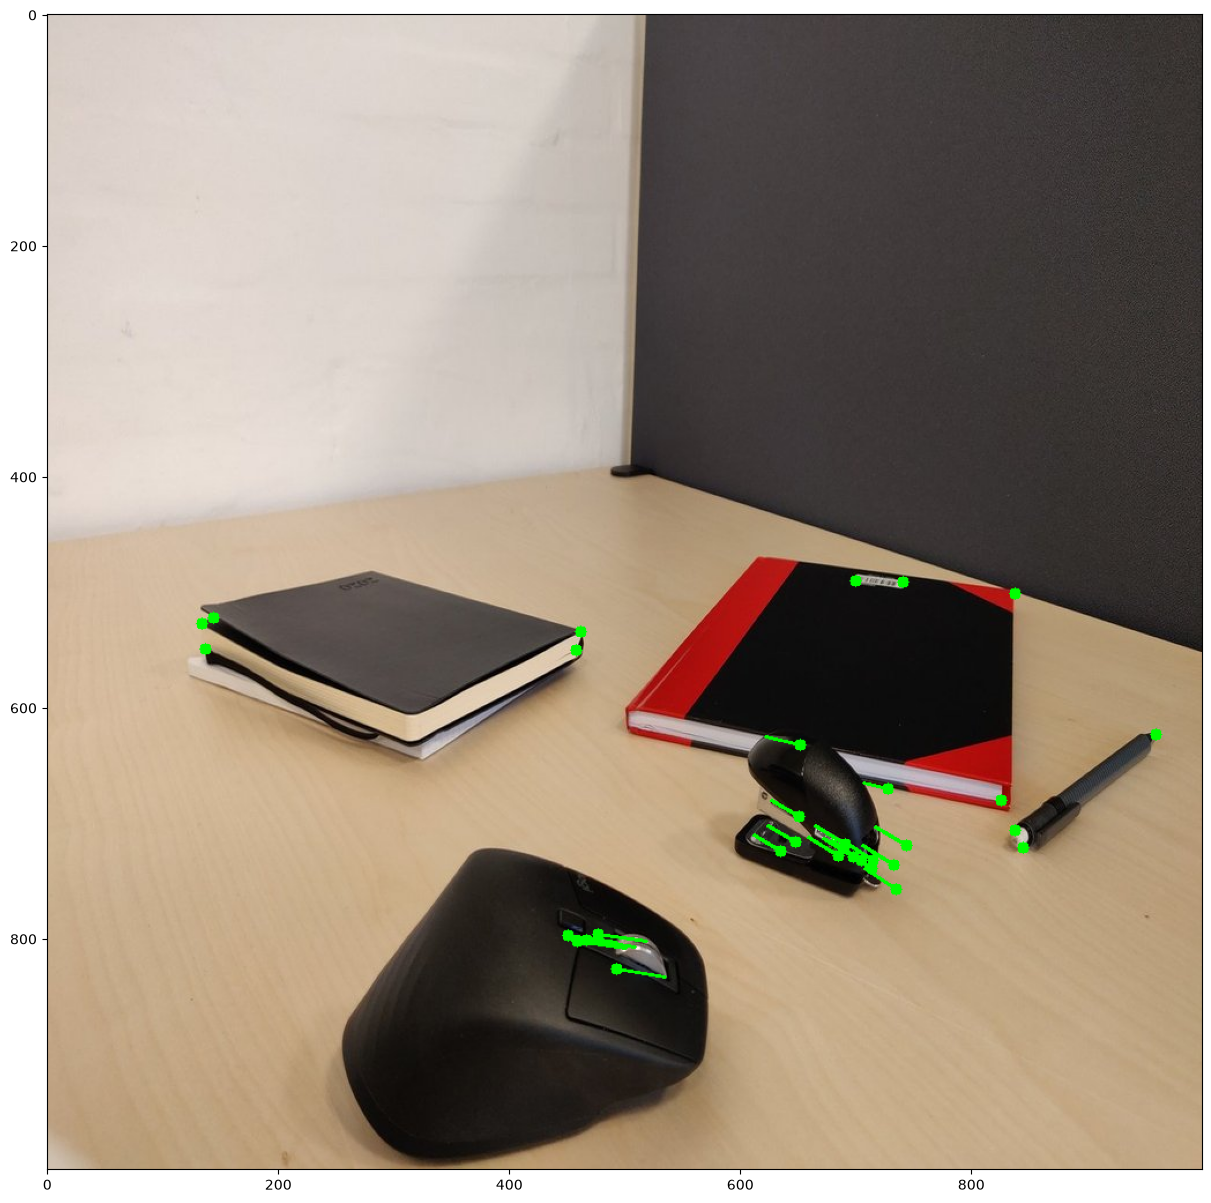

In [15]:
cimg2 = img2.copy()
for i in range(len(feat1)):
    f10=int(feat1[i][0][0])
    f11=int(feat1[i][0][1])
    f20=int(feat2[i][0][0])
    f21=int(feat2[i][0][1])
    cv2.line(cimg2, (f10,f11), (f20, f21), (0, 255, 0), 2)
    cv2.circle(cimg2, (f10, f11), 5, (0, 255, 0), -1)

plt.figure(figsize=(15,15))
plt.imshow(cimg2)

## Exercise 4a
Change the code such that only the keypoints that have moved will be showed in the image.


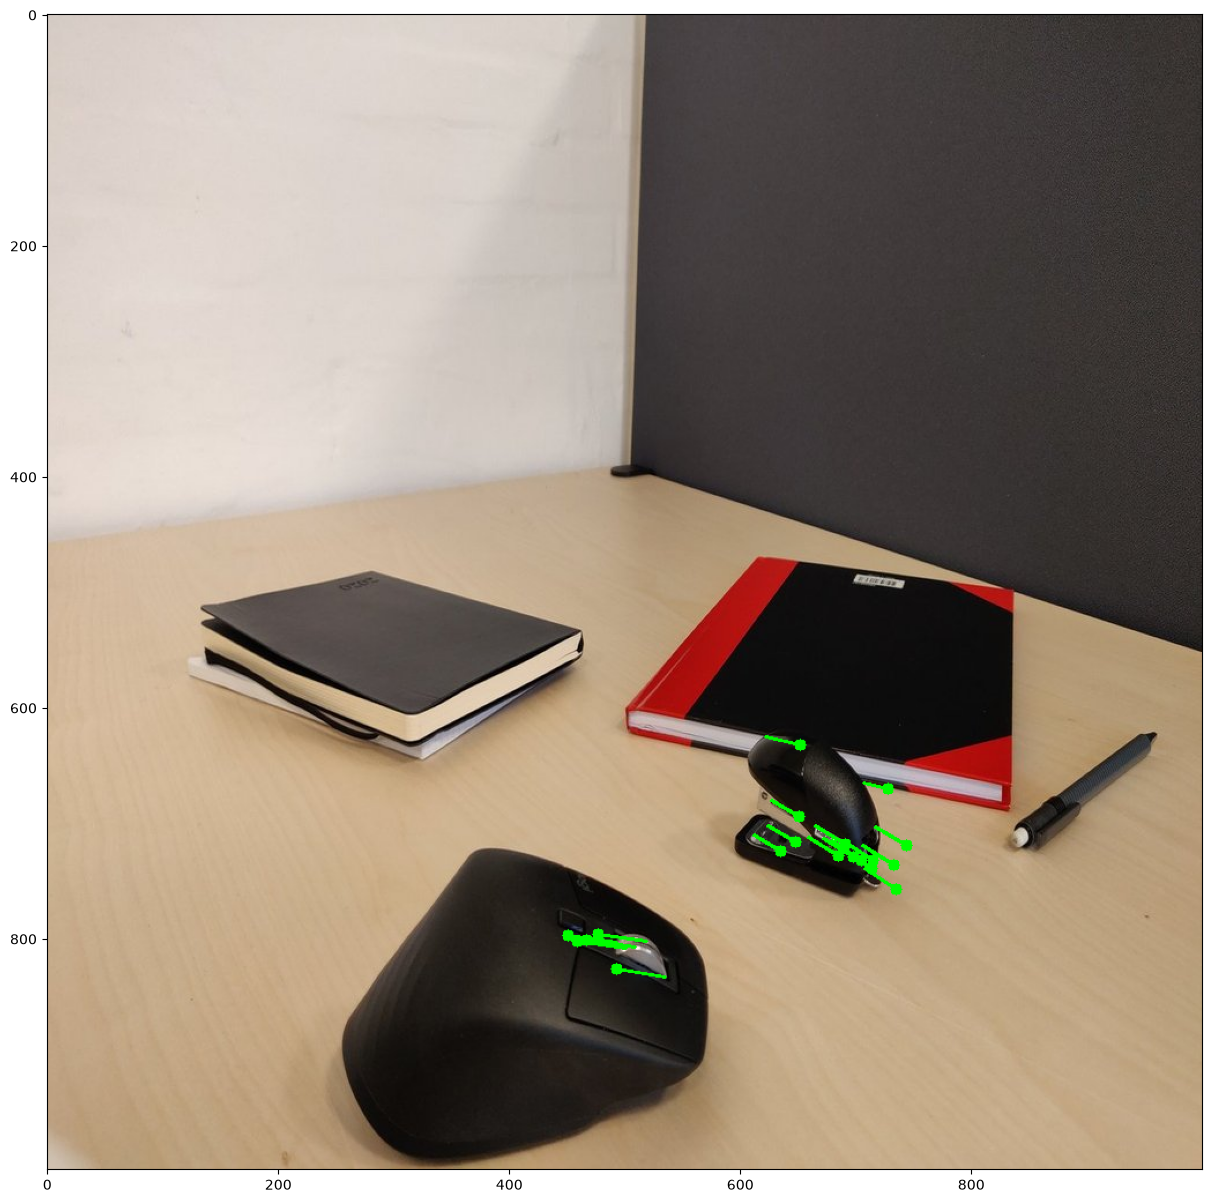

In [17]:
cimg2 = img2.copy()
for i in range(len(feat1)):
    f10=int(feat1[i][0][0])
    f11=int(feat1[i][0][1])
    f20=int(feat2[i][0][0])
    f21=int(feat2[i][0][1])
    if (abs(f10-f20) + abs(f11-f21)) > 5:
        cv2.line(cimg2, (f10,f11), (f20, f21), (0, 255, 0), 2)
        cv2.circle(cimg2, (f10, f11), 5, (0, 255, 0), -1)

plt.figure(figsize=(15,15))
plt.imshow(cimg2)

## Dense Optical Flow
The sparse optical flow finds the flow of the detected keypoints. We will now try to use dense optical flow which, finds the flow of all the points in the picture. 
For this example we use the same two images, so we don't have to load them again. To find the optical flow, we use the function [`cv2.calcOpticalFlowFarneback`](https://docs.opencv.org/4.7.0/dc/d6b/group__video__track.html#ga5d10ebbd59fe09c5f650289ec0ece5af). Check out the description to see what all the different parameters do, and try to change them to see the difference.

In [112]:
flow = cv2.calcOpticalFlowFarneback(gray1, gray2, None,
                                    0.5, # pyr_scale, parameter specifying the image scale (<1) to build pyramids for each image; pyr_scale=0.5 means a classical pyramid, where each next layer is twice smaller than the previous one
                                    200, # levels, parameter specifying the number of pyramid layers including the initial image
                                    50, # winsize, parameter specifying the averaging window size
                                    500, # iterations, parameter specifying the number of iterations to perform
                                    9, # poly_n, parameter specifying the size of the pixel neighborhood used to find polynomial expansion in each pixel, larger values mean that the image will be approximated with smoother surfaces, yielding more robust algorithm and more blurred motion field, typically poly_n =5 or 7
                                    1.7, # poly_sigma, parameter specifying the standard deviation of the Gaussian window used to smooth derivatives
                                    cv2.OPTFLOW_FARNEBACK_GAUSSIAN) # flags, operation flags that can be a combination of the following: OPTFLOW_USE_INITIAL_FLOW, OPTFLOW_FARNEBACK_GAUSSIAN
print(flow[4,1,...])

[1.96241745e-05 1.03390484e-07]


The function returns an array containing the flow vector for every pixel. This can be changed to a magnitude and an angle using the function [`cv2.cartToPolar`](https://docs.opencv.org/4.7.0/d2/de8/group__core__array.html#gac5f92f48ec32cacf5275969c33ee837d). 

14939/1000000


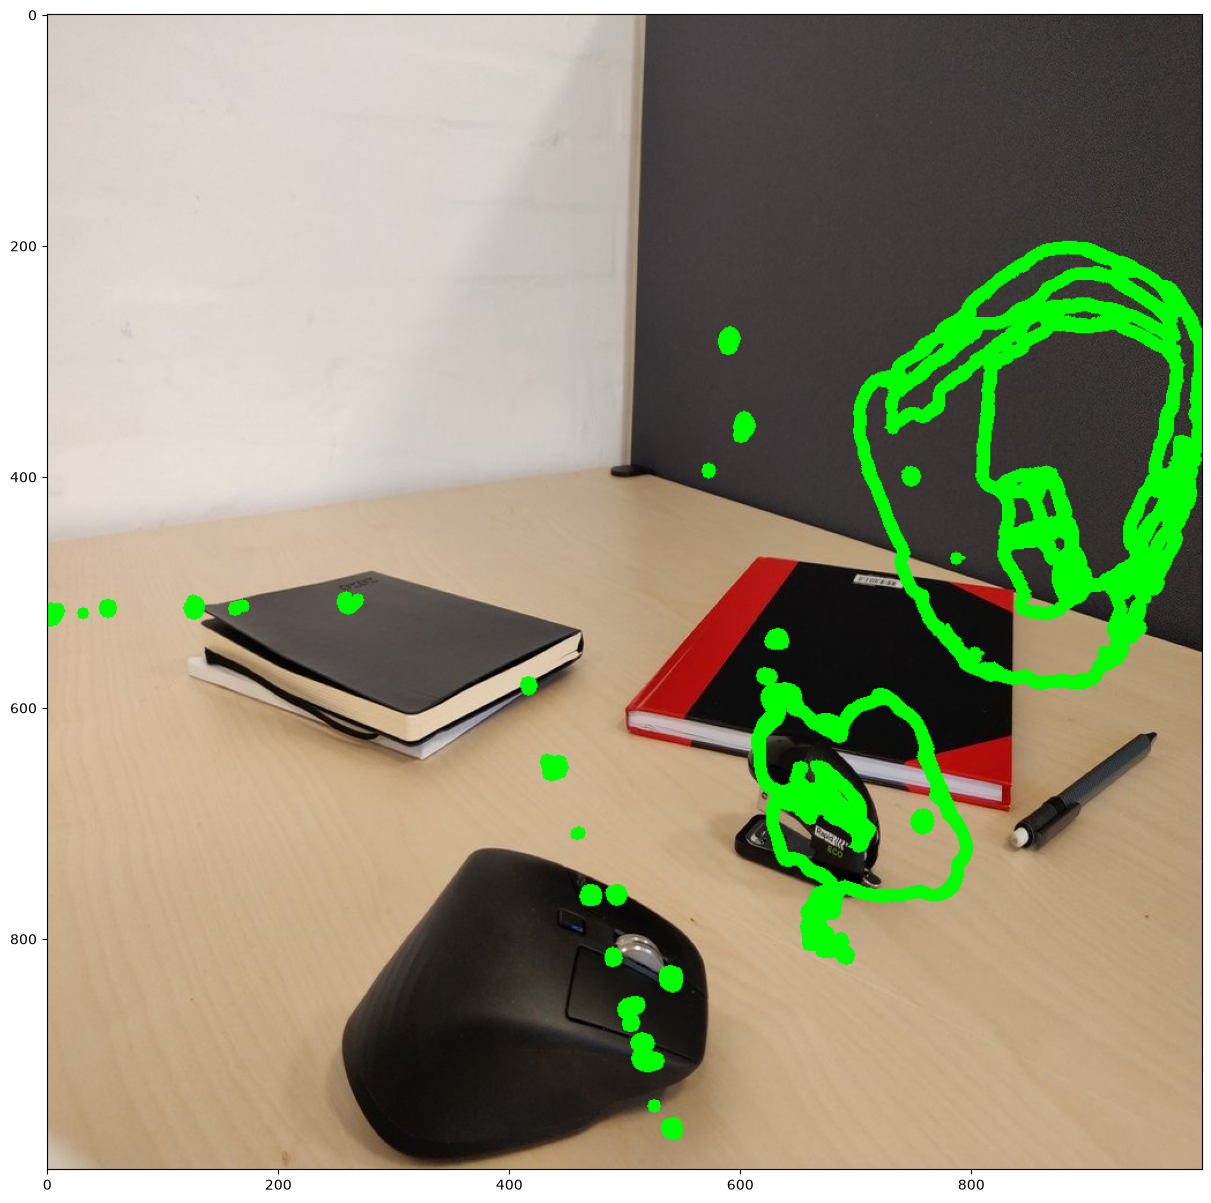

In [111]:
cimg2 = img2.copy()
counts = 0
for i in range(1000):
    for j in range(1000):
        f10=i
        f11=j
        f20=int(i + flow[i,j,0])
        f21=int(j + flow[i,j,1])
        if (abs(f10-f20) + abs(f11-f21)) > 2 and (abs(f10-f20) + abs(f11-f21)) < 8:
            #print(f10, f11, f20, f21)
            counts += 1
            cv2.line(cimg2, (f10,f11), (f20, f21), (0, 255, 0), 2)
            cv2.circle(cimg2, (f10, f11), 5, (0, 255, 0), -1)
plt.figure(figsize=(15,15))
plt.imshow(cimg2)
print(str(counts) + "/"+ str(1000*1000))

# Exercise 4b
Find a way to represent the flow in the image, for example, by drawing vectors the relevant places or by making a new image with colors representing the flow of every pixel. An example of retrieving the magnitude and angle is shown below, which you can use if you like. 

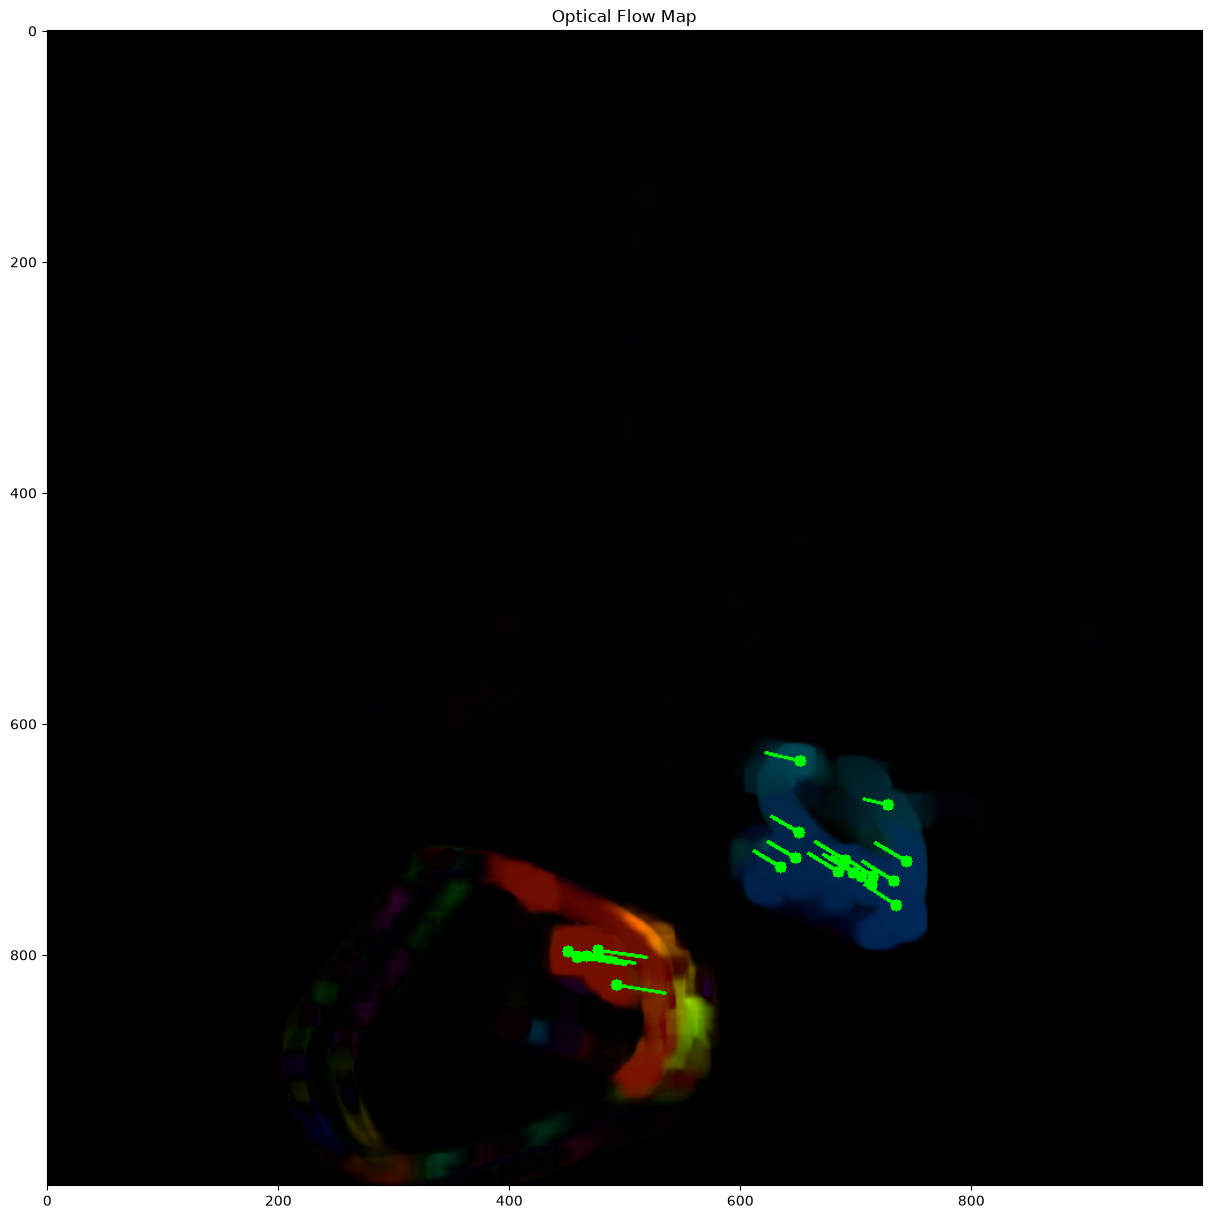

In [100]:
mag, ang = cv2.cartToPolar(flow[:,:,0], flow[:,:,1], angleInDegrees=True) # Retrieving the magnitude and angle of every pixel


### Fill in some code to represent the flow here ###
flow_image = np.zeros((1000, 1000, 3), dtype=np.uint8)
flow_image[..., 0] = ang/2 # The angle of the flow vector is represented as hue in the HSV color space
flow_image[..., 1] = 255 # Saturation
flow_image[..., 2] = cv2.normalize(mag, None, 0, 255, cv2.NORM_MINMAX) # The magnitude of the flow vector is represented as value in the HSV color space, stronger flow vectors are brighter in the HSV color space
flow_map = cv2.cvtColor(flow_image, cv2.COLOR_HSV2RGB) # Convert HSV to RGB



for i in range(len(feat1)):
    f10=int(feat1[i][0][0])
    f11=int(feat1[i][0][1])
    f20=int(feat2[i][0][0])
    f21=int(feat2[i][0][1])
    if (abs(f10-f20) + abs(f11-f21)) > 5:
        cv2.line(flow_map, (f10,f11), (f20, f21), (0, 255, 0), 2)
        cv2.circle(flow_map, (f10, f11), 5, (0, 255, 0), -1)
# Flow with Hue and Saturation key

plt.figure(figsize=(15,15))
plt.title("Optical Flow Map")
plt.imshow(flow_map)

